In [1]:
#@title 1) Setup
!pip install -q numpy pandas matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9,5)
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

print("Ready")

Ready


In [2]:
#@title 2) Make the dataset
N = 12000

days = pd.date_range("2024-01-01", "2024-03-31", freq="D")
w = np.where(days.dayofweek < 5, 1.0, 0.6)
w = w * np.linspace(0.9, 1.2, len(days))
w = w/w.sum()
dix = rng.choice(len(days), N, p=w)

hp = np.array([1,.4,.25,.2,.3,.8,1.6,3,6,9,11,10,8,9,11,10,9,7,6,6,8,7,4,2]); hp/=hp.sum()
h = rng.choice(24,N,p=hp); m=rng.integers(0,60,N); s=rng.integers(0,60,N)
dt = pd.to_datetime(pd.Index(days[dix])) + pd.to_timedelta(h,'h')+pd.to_timedelta(m,'m')+pd.to_timedelta(s,'s')

src = rng.choice(["Organic","Direct","Social","Email","Referral","Paid"], N, p=[.34,.2,.16,.1,.12,.08])
dev = rng.choice(["Desktop","Mobile","Tablet"], N, p=[.46,.42,.12])
br  = rng.choice(["Chrome","Safari","Firefox","Edge"], N, p=[.55,.33,.08,.04])
cty = rng.choice(["India","US","UK","Germany","Japan","Brazil"], N, p=[.3,.26,.14,.12,.1,.08])
lp  = rng.choice(["/home","/products","/blog","/pricing","/about","/contact"], N, p=[.28,.22,.18,.14,.1,.08])

bp = {"Organic":.32,"Direct":.28,"Social":.48,"Email":.22,"Referral":.3,"Paid":.52}
adj= {"/home":0,"/products":-.04,"/blog":.06,"/pricing":-.14,"/about":.1,"/contact":.02}
pb = np.array([bp[x] for x in src])+np.array([adj[x] for x in lp])+np.where(dev=="Mobile",.05,0)
pb = np.clip(pb,.02,.95)
bce= (rng.random(N)<pb).astype(int)

dur = rng.lognormal(np.log(150),.9,N)
dur = np.where(bce==1,rng.uniform(3,40,N),dur)
dur*=np.where(dev=="Mobile",.9,1); dur*=np.where(lp=="/blog",1.3,1)
dur = np.clip(dur,1,3600)

pv = np.where(bce==1,1,1+rng.poisson(np.clip(dur/200,.4,8))).astype(int); pv=np.clip(pv,1,25)
ic = np.where(bce==1,0,rng.poisson(pv*.8)).astype(int)

rev=0.0
buy=rng.random(N)<(.03 + np.where(lp=="/pricing",.12,0)+np.where(src=="Email",.07,0))
rev=np.where(buy,rng.lognormal(np.log(40),.7,N),0).round(2)

df = pd.DataFrame({
 "date":dt,
 "source":src,
 "device":dev,
 "browser":br,
 "country":cty,
 "page":lp,
 "pages":pv,
 "seconds":dur.round(1),
 "clicks":ic,
 "bounce":bce,
 "revenue":rev
})
df["session_id"] = [f"s{i:06d}" for i in range(len(df))]

# add a bit of mess on purpose
df2 = df.copy()
df2.loc[rng.choice(df2.index,150,replace=False),"seconds"] = np.nan
df2.loc[rng.choice(df2.index,80,replace=False),"browser"] = np.nan
df2.loc[rng.choice(df2.index,60,replace=False),"revenue"] = -df2.loc[rng.choice(df2.index,60,replace=False),"revenue"].abs()
df2 = pd.concat([df2, df2.sample(90, random_state=SEED)], ignore_index=True)
df2 = df2.sample(frac=1, random_state=SEED).reset_index(drop=True)

df = df2.copy()
print(df.shape)
df.head()

(12090, 12)


,date,source,device,browser,country,page,pages,seconds,clicks,bounce,revenue,session_id
0,2024-01-16 10:36:33,Organic,Mobile,Chrome,Germany,/blog,1,43.6,0,1,0.0,s000468
1,2024-02-02 14:28:25,Organic,Desktop,Chrome,UK,/products,1,5.2,0,1,0.0,s003219
2,2024-01-17 20:23:44,Direct,Mobile,Chrome,US,/blog,3,397.4,2,0,0.0,s000538
3,2024-01-25 19:53:18,Paid,Tablet,Chrome,Japan,/home,1,21.4,0,1,0.0,s004691
4,2024-01-18 15:47:31,Organic,Desktop,Chrome,India,/products,2,488.2,1,0,0.0,s006384


In [3]:
#@title 3) First look
print("Rows/Cols:", df.shape)
print("\nTypes:")
print(df.dtypes)
print("\nMissing:")
print(df.isna().sum())
print("\nDupes:", df.duplicated().sum())
df.describe().round(2)

Rows/Cols: (12090, 12)

Types:
date          datetime64[ns]
source                object
device                object
browser               object
country               object
page                  object
pages                  int64
seconds              float64
clicks                 int64
bounce                 int64
revenue              float64
session_id            object
dtype: object

Missing:
date            0
source          0
device          0
browser        81
country         0
page            0
pages           0
seconds       153
clicks          0
bounce          0
revenue        60
session_id      0
dtype: int64

Dupes: 90


,date,pages,seconds,clicks,bounce,revenue
count,12090,12090.00,11937.00,12090.00,12090.00,12030.00
mean,2024-02-17 06:41:24.005624832,1.74,154.78,1.11,0.35,2.64
min,2024-01-01 00:06:13,1.00,2.70,0.00,0.00,0.00
25%,2024-01-25 16:06:58.500000,1.00,27.20,0.00,0.00,0.00
50%,2024-02-18 15:53:30.500000,1.00,74.90,0.00,0.00,0.00
75%,2024-03-11 10:31:32.249999872,2.00,191.20,2.00,1.00,0.00
max,2024-03-31 23:46:52,18.00,3600.00,18.00,1.00,381.75
std,NaN,1.40,237.67,1.69,0.48,14.27


In [4]:
#@title 4) Clean up
data = df.copy()

# drop dupes
data = data.drop_duplicates().reset_index(drop=True)

# fix types
data["seconds"] = pd.to_numeric(data["seconds"], errors="coerce")
data["revenue"] = pd.to_numeric(data["revenue"], errors="coerce")

# fix bad values
data.loc[data["seconds"] < 0, "seconds"] = np.nan
data.loc[data["seconds"] > 7200, "seconds"] = np.nan
data.loc[data["revenue"] < 0, "revenue"] = 0
data.loc[(data["bounce"]==0) & (data["pages"]==0), "pages"] = 1

# fill
data["seconds"] = data.groupby("device", observed=True)["seconds"].transform(lambda x: x.fillna(x.median())).fillna(data["seconds"].median())
data["browser"] = data["browser"].fillna(data["browser"].mode(dropna=True)[0])

# derive
data["date"] = pd.to_datetime(data["date"])
data["hour"] = data["date"].dt.hour
data["dow"]  = data["date"].dt.day_name()
data["min"]  = data["seconds"]/60
data["conv"] = (data["revenue"]>0).astype(int)

print("After clean:", data.shape)
print("Missing left:", data.isna().sum().sum())
data.head()

After clean: (12000, 16)
Missing left: 60


,date,source,device,browser,country,page,pages,seconds,clicks,bounce,revenue,session_id,hour,dow,min,conv
0,2024-01-16 10:36:33,Organic,Mobile,Chrome,Germany,/blog,1,43.6,0,1,0.0,s000468,10,Tuesday,0.726667,0
1,2024-02-02 14:28:25,Organic,Desktop,Chrome,UK,/products,1,5.2,0,1,0.0,s003219,14,Friday,0.086667,0
2,2024-01-17 20:23:44,Direct,Mobile,Chrome,US,/blog,3,397.4,2,0,0.0,s000538,20,Wednesday,6.623333,0
3,2024-01-25 19:53:18,Paid,Tablet,Chrome,Japan,/home,1,21.4,0,1,0.0,s004691,19,Thursday,0.356667,0
4,2024-01-18 15:47:31,Organic,Desktop,Chrome,India,/products,2,488.2,1,0,0.0,s006384,15,Thursday,8.136667,0


In [5]:
#@title 5) Key numbers
print("Total sessions :", len(data))
print("Bounce rate     :", f"{data['bounce'].mean():.1%}")
print("Conversion rate :", f"{data['conv'].mean():.2%}")
print("Avg time(min)   :", f"{data['min'].mean():.1f}")
print("Avg pages       :", f"{data['pages'].mean():.1f}")
print("Revenue/session :", f"{data['revenue'].mean():.2f}")

print("\n-- By device --")
print(data.groupby("device", observed=True)[["seconds","pages","revenue","bounce"]].mean().round(2))

print("\n-- By source --")
print(data.groupby("source", observed=True)[["seconds","pages","revenue","bounce"]].mean().round(2))

print("\n-- Top pages --")
print(data["page"].value_counts())

Total sessions : 12000
Bounce rate     : 35.4%
Conversion rate : 5.12%
Avg time(min)   : 2.6
Avg pages       : 1.7
Revenue/session : 2.63

-- By device --
         seconds  pages  revenue  bounce
device                                  
Desktop   168.40   1.83     2.70    0.32
Mobile    131.21   1.62     2.52    0.40
Tablet    174.24   1.83     2.71    0.31

-- By source --
          seconds  pages  revenue  bounce
source                                   
Direct     161.70   1.80     2.89    0.29
Email      175.79   1.88     5.62    0.24
Organic    159.03   1.78     2.31    0.32
Paid       123.44   1.55     2.73    0.53
Referral   162.73   1.76     1.69    0.32
Social     125.64   1.60     1.67    0.51

-- Top pages --
page
/home        3415
/products    2586
/blog        2202
/pricing     1643
/about       1184
/contact      970
Name: count, dtype: int64


In [6]:
#@title 6) Time based
dti = data.set_index("date").sort_index()

daily = dti.resample("D").agg(sess=("session_id","count"), avg_s=("seconds","mean"), bounce=("bounce","mean"), rev=("revenue","sum"))
weekly= dti.resample("W").agg(sess=("session_id","count"), rev=("revenue","sum"))
hourly= dti.groupby("hour")[["session_id","revenue","bounce"]].agg(sess=("session_id","count"), avg_rev=("revenue","mean"), br=("bounce","mean"))

print("Daily head:")
print(daily.head().round(2))
print("\nBy hour top:")
print(hourly.sort_values("sess", ascending=False).head().round(2))

Daily head:
            sess   avg_s  bounce     rev
date                                    
2024-01-01   130  157.27    0.35  174.65
2024-01-02   113  123.99    0.36  177.88
2024-01-03   134  182.16    0.28  351.63
2024-01-04   129  187.46    0.26  491.73
2024-01-05   145  120.52    0.38  503.26

By hour top:
      sess  avg_rev    br
hour                     
14    1021     3.35  0.37
10     968     2.39  0.37
11     938     2.21  0.35
15     892     2.85  0.34
16     844     2.25  0.37


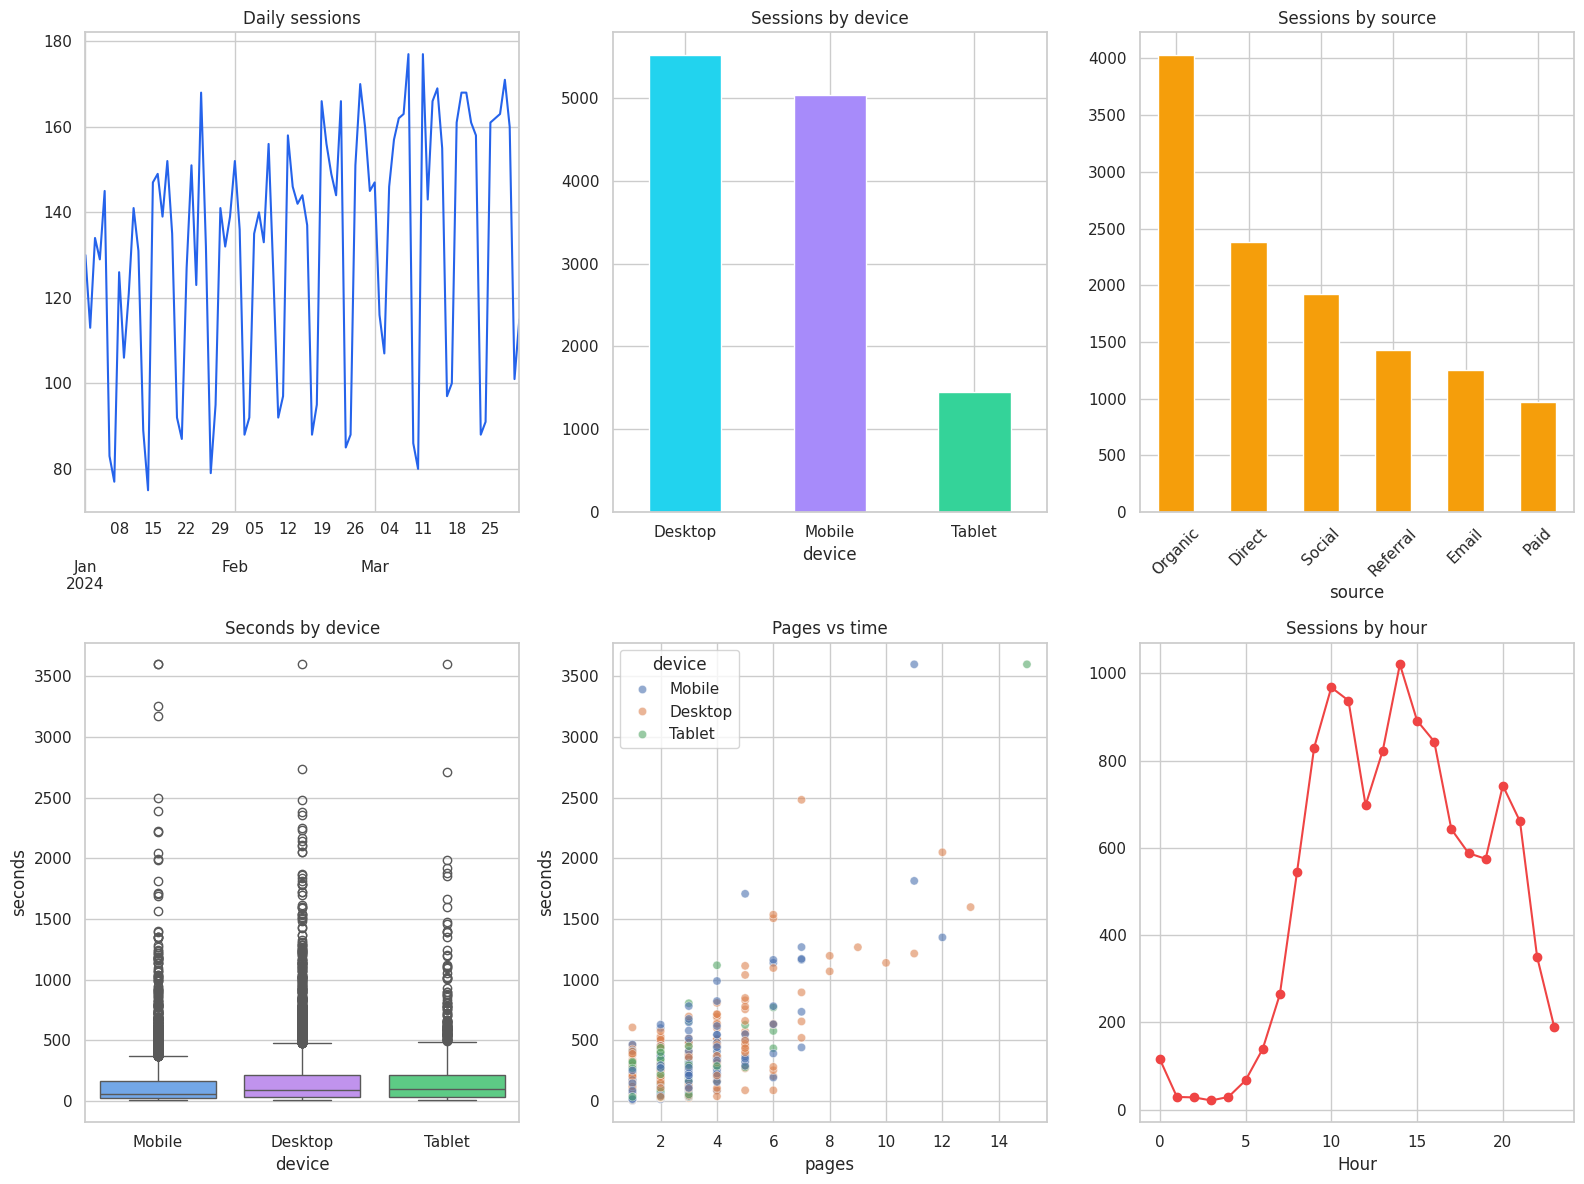

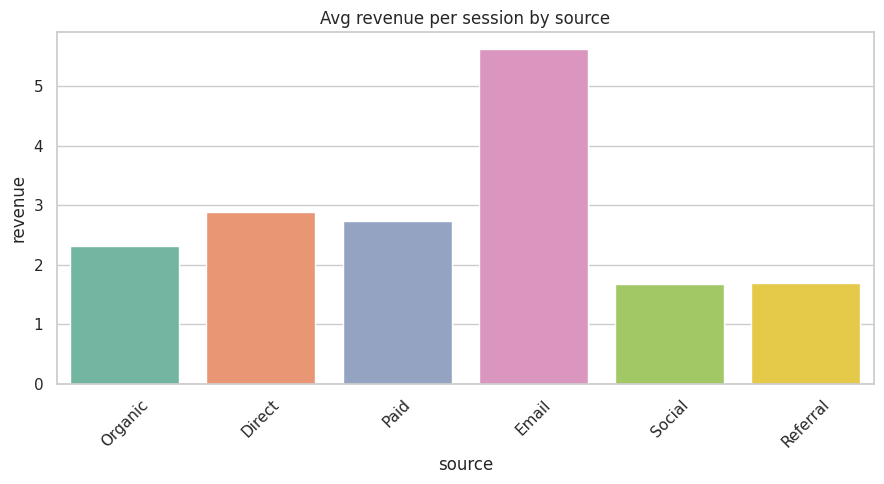

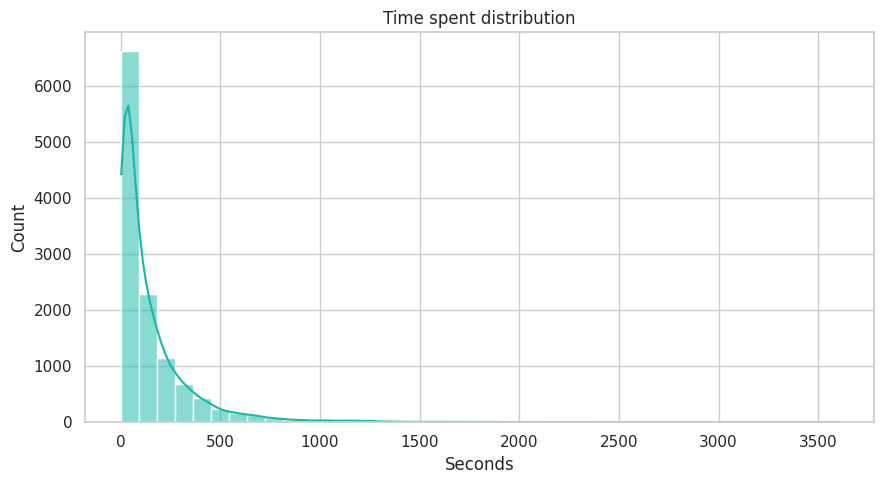

In [7]:
#@title 7) All plots
fig = plt.figure(figsize=(16,12))

# 1) Daily traffic
ax1 = plt.subplot(2,3,1)
daily["sess"].plot(ax=ax1, color="#2563eb")
ax1.set_title("Daily sessions")
ax1.set_xlabel("")

# 2) By device
ax2 = plt.subplot(2,3,2)
data["device"].value_counts().plot(kind="bar", ax=ax2, color=["#22d3ee","#a78bfa","#34d399"])
ax2.set_title("Sessions by device")
ax2.tick_params(axis='x', rotation=0)

# 3) By source
ax3 = plt.subplot(2,3,3)
data["source"].value_counts().plot(kind="bar", ax=ax3, color="#f59e0b")
ax3.set_title("Sessions by source")
ax3.tick_params(axis='x', rotation=45)

# 4) Time spent by device
ax4 = plt.subplot(2,3,4)
sns.boxplot(data=data, x="device", y="seconds", ax=ax4, palette=["#60a5fa","#c084fc","#4ade80"])
ax4.set_title("Seconds by device")

# 5) Pages vs seconds
ax5 = plt.subplot(2,3,5)
sns.scatterplot(data=data.sample(1500, random_state=SEED), x="pages", y="seconds", hue="device", alpha=0.6, ax=ax5)
ax5.set_title("Pages vs time")

# 6) Hourly load
ax6 = plt.subplot(2,3,6)
hourly["sess"].plot(ax=ax6, marker="o", color="#ef4444")
ax6.set_title("Sessions by hour")
ax6.set_xlabel("Hour")

plt.tight_layout()
plt.show()

# Extra focused ones
plt.figure(figsize=(9,5))
sns.barplot(data=data, x="source", y="revenue", estimator=np.mean, errorbar=None, palette="Set2")
plt.title("Avg revenue per session by source")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,5))
sns.histplot(data["seconds"], bins=40, kde=True, color="#14b8a6")
plt.title("Time spent distribution")
plt.xlabel("Seconds")
plt.tight_layout()
plt.show()

In [8]:
#@title 8) Takeaway
best_src = data.groupby("source")["revenue"].mean().idxmax()
peak_h   = hourly["sess"].idxmax()
top_dev  = data["device"].value_counts().idxmax()

print("Quick take")
print("- Most visits come from:", top_dev)
print("- Best source for revenue:", best_src)
print("- Busiest hour:", peak_h)
print("- Overall bounce:", f"{data['bounce'].mean():.1%}")
print("- Overall conversion:", f"{data['conv'].mean():.2%}")

Quick take
- Most visits come from: Desktop
- Best source for revenue: Email
- Busiest hour: 14
- Overall bounce: 35.4%
- Overall conversion: 5.12%


# Comprehensive Website Visitor Behaviour Analysis Project

This project applies computational techniques across five distinct stages mapped directly to our curriculum units:

* **Unit I (NumPy Basics):** Creating multi-dimensional ndarrays for session tracking metrics, array operations, vectorization for traffic simulation, universal functions (ufuncs), boolean and fancy indexing for metric thresholding, array transposing, and pseudo-random generation of traffic distributions[cite: 1, 2].
* **Unit II (Pandas Basics & Data Loading):** Series and DataFrame index manipulation, reindexing time-series data, dropping unnecessary log axes, sorting and ranking visitor engagement metrics, and computing descriptive summary statistics[cite: 1, 2].
* **Unit III (Data Cleaning, Transformation & Wrangling):** Filtering out missing/null tracking entries, filling missing visitor attributes, mapping/replacing values, discretization/binning of session durations (e.g., Short/Medium/Long), hierarchical indexing, and joining/merging user profile data with session clickstreams[cite: 1, 2].
* **Unit IV (Data Aggregation, Group Operations & Time Series):** Advanced split-apply-combine group operations by traffic channel/device type, column-wise aggregations, date-time parsing, time series indexing, subsetting, and frequency resampling (daily to weekly traffic downsampling)[cite: 1, 2].
* **Unit V (Plotting & Visualization):** Customized Matplotlib and Seaborn visualization layouts, including traffic trend line plots, device distribution bar charts, session length histograms and density plots, scatter plots for engagement vs. revenue, and categorical facet grids[cite: 1, 2].

---

## Course Outcomes (COs) Alignment

This project directly demonstrates and achieves the following official course competencies:

* **CO1 (Unit I):** Apply NumPy operations such as array creation, indexing, arithmetic computations, transposition, and random number generation to efficiently perform numerical and website session data manipulation tasks[cite: 1].
* **CO2 (Unit II):** Perform data manipulation, analysis, and summarization on structured website tracking datasets by utilizing Pandas data structures and core functionalities[cite: 1].
* **CO3 (Unit III):** Apply data cleaning and wrangling techniques using Pandas to handle missing clickstream data, transform and categorize engagement values, perform hierarchical indexing, merge auxiliary user datasets, and prepare raw logs for meaningful analysis[cite: 1].
* **CO4 (Unit IV):** Summarize and analyze visitor behavior using group operations, and handle time series traffic data by converting timestamps, selecting time-based ranges, and performing resampling with Pandas[cite: 1].
* **CO5 (Unit V):** Create and customize a variety of visualizations using Matplotlib and Seaborn, including line plots, bar charts, histograms, scatter plots, and categorical plots, to effectively communicate visitor behavior insights[cite: 1].